# Data Exploration and Preprocessing — Bayyinah Burnout Models

This notebook explores the dataset and builds the preprocessing used by both burnout models (regression and classification).

**Dataset:** [Mental Health & Burnout in Tech Workers 2026](https://www.kaggle.com/datasets/mohankrishnathalla/mental-health-and-burnout-in-tech-workers-2026)

The functions defined here are also saved in `preprocessing.py`, which the model notebooks and the Bayyinah backend import, so every part of the project uses exactly the same steps.

**Contents**
1. Data overview
2. Data quality checks
3. Exploratory data analysis
4. Preprocessing
    - 4.1 Dropping leakage columns
    - 4.2 Outliers
    - 4.3 Logic rules
    - 4.4 Train/test split
    - 4.5 Preprocessing pipeline

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

plt.rcParams["figure.dpi"] = 110

In [2]:
DATA_PATH = "mental_health_burnout_tech_2026.csv"
TARGET = "burnout_score"
SEED = 42

# burnout_level is just the target split into groups -> leakage.
# phq9/gad7 are depression/anxiety scores measured at the same time as burnout,
# and the last two columns are results of burnout, not causes.
DROP_COLS = [
    "employee_id", "burnout_level",
    "phq9_score", "phq9_category", "gad7_score", "gad7_category",
    "seeks_mental_health_support", "job_change_intention",
]

EXCLUDED_GENDERS = ["Non-binary"]

## 1. Data overview

In [3]:
def load_data(path=DATA_PATH):
    df = pd.read_csv(path)
    df = df[~df["gender"].isin(EXCLUDED_GENDERS)].reset_index(drop=True)
    return df

In [4]:
df = load_data()
print(df.shape)
df.head()

(96006, 36)


,employee_id,age,gender,country,job_role,seniority_level,years_experience,years_at_company,company_size,industry,...,autonomy_score,stress_score,burnout_score,phq9_score,phq9_category,gad7_score,gad7_category,burnout_level,seeks_mental_health_support,job_change_intention
0,1,33,Male,India,Software Engineer,Lead,11,6.4,Small (51-200),Healthcare Tech,...,6.1,10.0,10.0,19,Moderately Severe (15-19),12,Moderate (10-14),Severe,1,1
1,3,36,Prefer not to say,USA,Software Engineer,Lead,14,5.6,Mid (201-1000),Fintech,...,4.1,8.9,8.5,8,Mild (5-9),9,Mild (5-9),Severe,0,1
2,6,22,Female,Brazil,Data Analyst,Principal,0,4.4,Startup (1-50),Social Media / AdTech,...,9.0,7.1,7.4,9,Mild (5-9),7,Mild (5-9),Severe,0,1
3,7,32,Male,USA,Data Analyst,Junior,10,2.3,Small (51-200),Consulting,...,4.8,6.7,3.8,2,None (0-4),5,Mild (5-9),Moderate,0,1
4,8,29,Female,Netherlands,DevOps Engineer,Mid,8,2.3,Large (1001-5000),AI / ML Startup,...,5.0,7.6,3.9,6,Mild (5-9),8,Mild (5-9),Moderate,0,0


In [5]:
df.dtypes.value_counts()

int64      15
float64    11
str        10
Name: count, dtype: int64

In [6]:
for c in df.select_dtypes(exclude="number").columns:
    print(f"{c} ({df[c].nunique()}): {df[c].value_counts().to_dict()}\n")

gender (3): {'Male': 65243, 'Female': 29759, 'Prefer not to say': 1004}

country (10): {'USA': 30767, 'India': 21094, 'UK': 9529, 'Canada': 7616, 'Germany': 6796, 'Australia': 5900, 'Brazil': 3885, 'Netherlands': 3805, 'Singapore': 3788, 'France': 2826}

job_role (12): {'Software Engineer': 19274, 'Data Scientist': 11570, 'ML Engineer': 9705, 'Backend Developer': 7709, 'Data Analyst': 7703, 'Frontend Developer': 7660, 'Product Manager': 7638, 'DevOps Engineer': 7622, 'Full Stack Developer': 6620, 'Cybersecurity Engineer': 3846, 'Cloud Engineer': 3758, 'QA Engineer': 2901}

seniority_level (6): {'Mid': 27008, 'Senior': 23847, 'Junior': 19410, 'Lead': 11428, 'Manager': 9520, 'Principal': 4793}

company_size (5): {'Mid (201-1000)': 24076, 'Large (1001-5000)': 21140, 'Startup (1-50)': 18986, 'Small (51-200)': 17366, 'Enterprise (5000+)': 14438}

industry (10): {'SaaS / Cloud': 19150, 'Fintech': 14489, 'E-commerce': 11563, 'AI / ML Startup': 11480, 'Healthcare Tech': 9588, 'Cybersecurity': 

## 2. Data quality checks

In [7]:
print("missing values:", df.isna().sum().sum())
print("duplicate rows:", df.duplicated().sum())
print("duplicate IDs: ", df["employee_id"].duplicated().sum())

missing values: 0


duplicate rows: 0
duplicate IDs:  0


In [8]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
employee_id,96006.0,49979.15,28870.24,1.0,24978.25,49952.5,74989.75,100000.0
age,96006.0,31.31,6.43,22.0,26.00,31.0,36.00,55.0
years_experience,96006.0,9.34,6.40,0.0,4.00,9.0,14.00,25.0
years_at_company,96006.0,2.49,2.45,0.1,0.70,1.7,3.50,15.0
salary_usd,96006.0,83305.55,39391.35,40000.0,46062.25,76671.5,109156.75,267961.0
work_hours_per_week,96006.0,47.10,5.24,35.0,44.00,47.0,51.00,72.0
meetings_per_day,96006.0,4.16,1.94,0.0,2.80,4.0,5.40,12.0
team_size,96006.0,18.00,12.60,2.0,8.00,16.0,25.00,59.0
sleep_hours_per_night,96006.0,6.10,1.00,3.0,5.40,6.1,6.80,10.0
exercise_days_per_week,96006.0,2.97,1.77,0.0,2.00,3.0,4.00,7.0


No missing values and no duplicates, so no rows need to be removed for quality reasons.

## 3. Exploratory data analysis

### Target variable

count    96006.00
mean         5.40
std          2.67
min          0.00
25%          3.50
50%          5.40
75%          7.40
max         10.00
Name: burnout_score, dtype: float64

skewness: -0.058
scores at exactly 0:  2.1%
scores at exactly 10: 6.5%


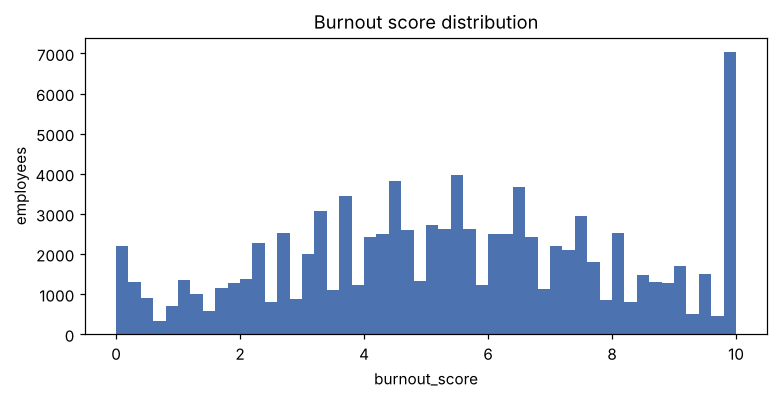

In [9]:
print(df[TARGET].describe().round(2))
print(f"\nskewness: {df[TARGET].skew():.3f}")
print(f"scores at exactly 0:  {(df[TARGET] == 0).mean():.1%}")
print(f"scores at exactly 10: {(df[TARGET] == 10).mean():.1%}")

plt.figure(figsize=(8, 3.5))
plt.hist(df[TARGET], bins=50, color="#4C72B0")
plt.xlabel("burnout_score")
plt.ylabel("employees")
plt.title("Burnout score distribution")
plt.show()

The score is between 0 and 10 and roughly symmetric, but some employees sit exactly at 0 or 10, so the extremes are capped.

In [10]:
df.groupby("burnout_level")[TARGET].agg(["min", "max", "count"]).sort_values("min")

,min,max,count
burnout_level,,,
Low,0.0,3.5,24856
Moderate,3.6,5.5,25256
High,5.6,7.0,18492
Severe,7.1,10.0,27402


`burnout_level` is not an independent column: each level is just a range of `burnout_score`.

### Correlations

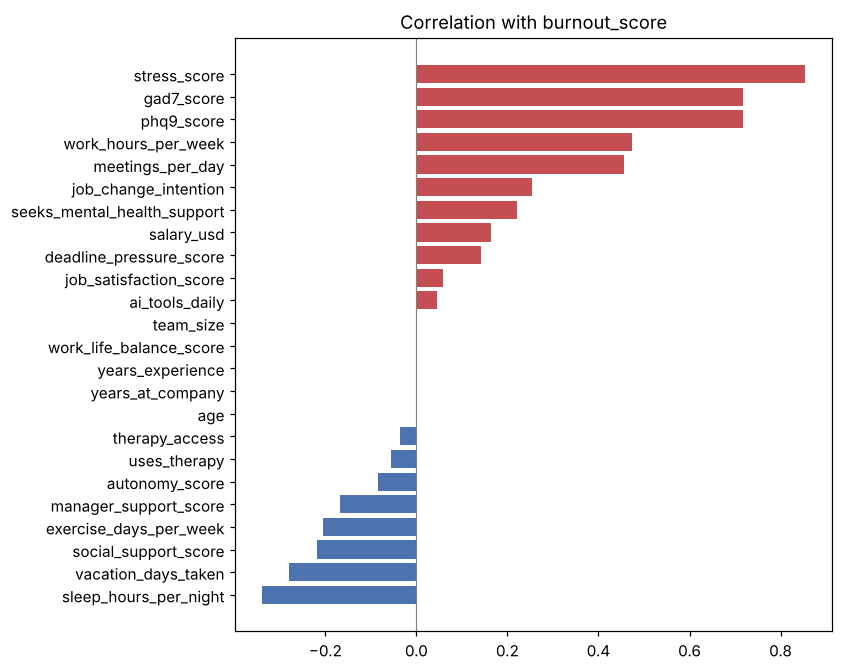

In [11]:
num_cols = df.select_dtypes("number").columns.drop(["employee_id", TARGET])
corr = df[num_cols].corrwith(df[TARGET]).sort_values()

plt.figure(figsize=(7, 7))
plt.barh(corr.index, corr.values, color=np.where(corr > 0, "#C44E52", "#4C72B0"))
plt.axvline(0, color="grey", lw=0.8)
plt.title("Correlation with burnout_score")
plt.show()

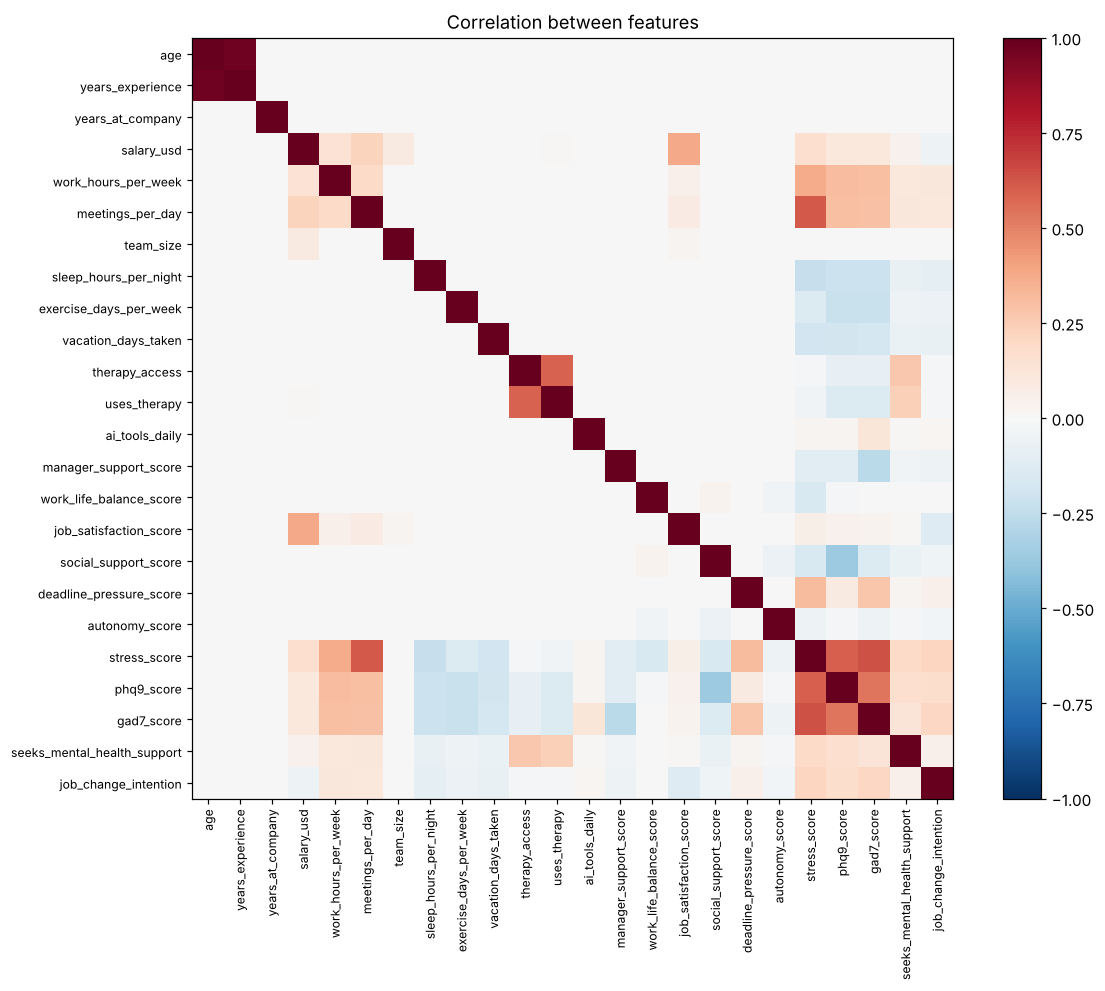

In [12]:
cm = df[num_cols].corr()
plt.figure(figsize=(11, 9))
plt.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(cm)), cm.columns, rotation=90, fontsize=8)
plt.yticks(range(len(cm)), cm.columns, fontsize=8)
plt.colorbar()
plt.title("Correlation between features")
plt.tight_layout()
plt.show()

### Categorical features

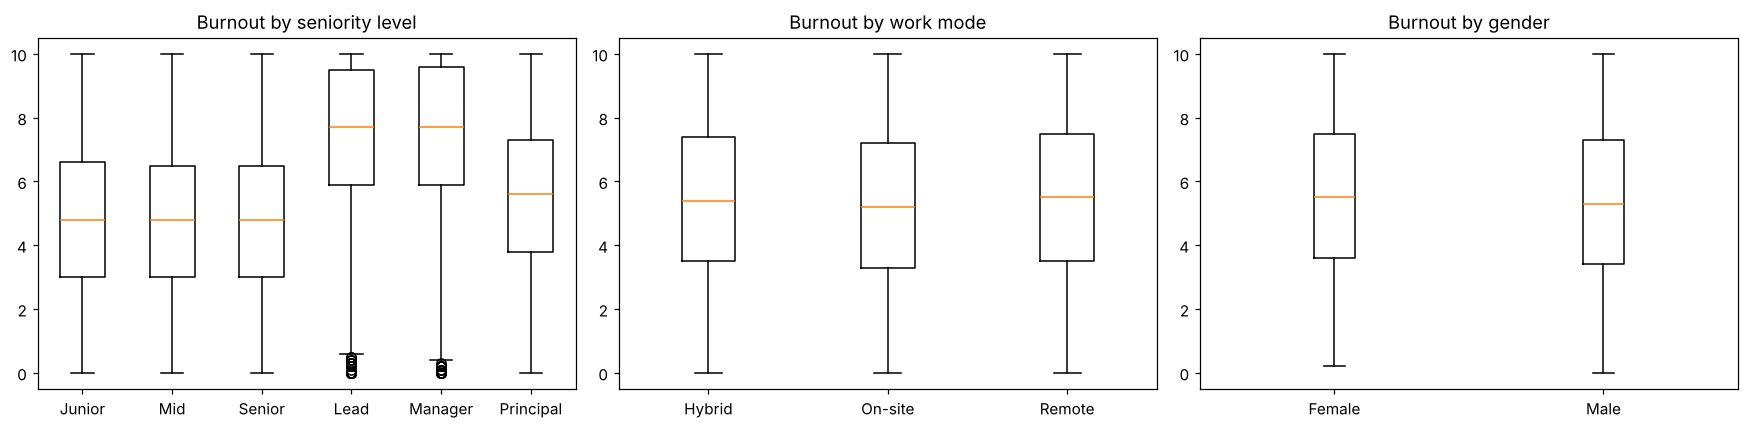

In [13]:
order = ["Junior", "Mid", "Senior", "Lead", "Manager", "Principal"]
modes = sorted(df.work_mode.unique())
genders = ["Female", "Male"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].boxplot([df.loc[df.seniority_level == l, TARGET] for l in order])
axes[0].set_xticks(range(1, len(order) + 1), order)
axes[0].set_title("Burnout by seniority level")
axes[1].boxplot([df.loc[df.work_mode == m, TARGET] for m in modes])
axes[1].set_xticks(range(1, len(modes) + 1), modes)
axes[1].set_title("Burnout by work mode")
axes[2].boxplot([df.loc[df.gender == g, TARGET] for g in genders])
axes[2].set_xticks(range(1, len(genders) + 1), genders)
axes[2].set_title("Burnout by gender")
plt.tight_layout()
plt.show()

In [14]:
features = ["seniority_level", "industry", "work_mode", "gender", "job_role", "company_size", "country"]
eta = {}
for c in features:
    g = df.groupby(c)[TARGET]
    eta[c] = (g.count() * (g.mean() - df[TARGET].mean()) ** 2).sum() / ((df[TARGET] - df[TARGET].mean()) ** 2).sum()
pd.Series(eta).sort_values(ascending=False).round(3).to_frame("share of variance explained (eta²)")

,share of variance explained (eta²)
seniority_level,0.166
industry,0.002
work_mode,0.001
gender,0.001
country,0.000
job_role,0.000
company_size,0.000


**What the EDA shows**
- `stress_score` has the strongest relationship with burnout, followed by work hours and meetings. Sleep and vacation days go the other way.
- `phq9_score` and `gad7_score` are also strongly correlated, but they are mental-health outcomes measured at the same time as burnout, not causes.
- Seniority is the only categorical feature that matters: Leads and Managers score clearly higher. Country, job role, industry, company size, work mode and gender explain almost nothing.
- `age` and `years_experience` are almost the same variable.

## 4. Preprocessing

### 4.1 Dropping leakage columns

| Dropped column(s) | Reason |
| --- | --- |
| employee_id | Just an ID |
| burnout_level | The target split into ranges (leakage) |
| phq9_score, phq9_category, gad7_score, gad7_category | Depression and anxiety scores measured at the same time as burnout |
| seeks_mental_health_support, job_change_intention | Results of burnout, not causes |

`stress_score` is kept as a predictor.

In [15]:
print("dropped:", DROP_COLS)
print("features left:", df.drop(columns=DROP_COLS + [TARGET]).shape[1])

dropped: ['employee_id', 'burnout_level', 'phq9_score', 'phq9_category', 'gad7_score', 'gad7_category', 'seeks_mental_health_support', 'job_change_intention']
features left: 27


### 4.2 Outliers (1.5 × IQR rule)

In [16]:
num = df.drop(columns=DROP_COLS + [TARGET]).select_dtypes("number")
outliers = {}
for c in num.columns:
    q1, q3 = num[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((num[c] < q1 - 1.5 * iqr) | (num[c] > q3 + 1.5 * iqr)).sum()
    if n:
        outliers[c] = n
pd.Series(outliers).sort_values(ascending=False).to_frame("outliers")

,outliers
uses_therapy,14552
years_at_company,4420
team_size,3289
meetings_per_day,633
sleep_hours_per_night,611
deadline_pressure_score,513
salary_usd,414
work_hours_per_week,336
vacation_days_taken,267
age,160


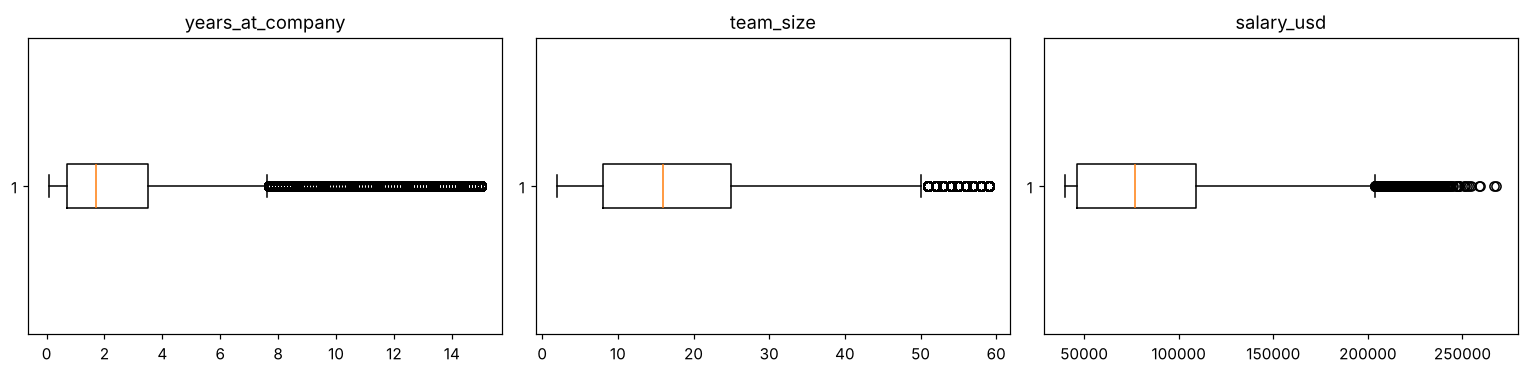

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, ["years_at_company", "team_size", "salary_usd"]):
    ax.boxplot(df[c], vert=False)
    ax.set_title(c)
plt.tight_layout()
plt.show()

These are long but realistic tails (long tenures, big teams, high salaries), not entry errors, so all rows are kept. Binary columns are flagged only because they are 0/1.

### 4.3 Logic rules

In [18]:
print("experience > age - 18:", (df.years_experience > df.age - 18).sum())
print("tenure > experience:  ", (df.years_at_company > df.years_experience).sum())

experience > age - 18: 118
tenure > experience:   17374


In [19]:
def fix_logic(X):
    # experience can't exceed working-age years, and tenure can't exceed experience
    X = X.copy()
    if {"age", "years_experience"}.issubset(X.columns):
        X["years_experience"] = X["years_experience"].clip(upper=X["age"] - 18)
    if {"years_experience", "years_at_company"}.issubset(X.columns):
        X["years_at_company"] = X["years_at_company"].clip(upper=X["years_experience"])
    return X

In [20]:
fixed = fix_logic(df)
print("after fixing:")
print("experience > age - 18:", (fixed.years_experience > fixed.age - 18).sum())
print("tenure > experience:  ", (fixed.years_at_company > fixed.years_experience).sum())

after fixing:
experience > age - 18: 0
tenure > experience:   0


The values are corrected instead of removing rows. The fix runs inside the pipeline (4.5), so it is applied the same way to training data, test data and new employees from the website.

### 4.4 Train/test split

In [21]:
def load_and_split(path=DATA_PATH):
    df = load_data(path)
    X = df.drop(columns=DROP_COLS + [TARGET])
    y = df[TARGET]

    # no date column, so a random split is fine.
    # burnout_score is continuous, so we group it into 10 bins to stratify the split
    y_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")
    return train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y_bins)

In [22]:
X_train, X_test, y_train, y_test = load_and_split()
print("train:", X_train.shape, " test:", X_test.shape)
print("train target mean/std:", round(y_train.mean(), 2), round(y_train.std(), 2))
print("test target mean/std: ", round(y_test.mean(), 2), round(y_test.std(), 2))

train: (76804, 27)  test: (19202, 27)
train target mean/std: 5.4 2.67
test target mean/std:  5.39 2.67


### 4.5 Preprocessing pipeline

Numeric columns: median imputation + scaling. Categorical columns: most-frequent imputation + one-hot encoding. The logic rules run first.

In [23]:
def build_preprocessor(X):
    num_cols = X.select_dtypes("number").columns.tolist()
    cat_cols = X.select_dtypes(exclude="number").columns.tolist()

    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    columns = ColumnTransformer([
        ("num", numeric, num_cols),
        ("cat", categorical, cat_cols),
    ])

    # fix the logic rules first, then impute / scale / encode
    return Pipeline([
        ("fix", FunctionTransformer(fix_logic)),
        ("columns", columns),
    ])

In [24]:
prep = build_preprocessor(X_train)
X_train_t = prep.fit_transform(X_train)
print("features before:", X_train.shape[1], " after preprocessing:", X_train_t.shape[1], "\n")
ct = prep.named_steps["columns"]
print("1. fix: logic rules (fix_logic)")
for i, (name, pipe, cols) in enumerate(ct.transformers_[:2], start=2):
    steps = " -> ".join(type(step).__name__ for _, step in pipe.steps)
    print(f"{i}. {name} ({len(cols)} columns): {steps}")

features before: 27  after preprocessing: 69 

1. fix: logic rules (fix_logic)
2. num (20 columns): SimpleImputer -> StandardScaler
3. cat (7 columns): SimpleImputer -> OneHotEncoder


Each model notebook puts this pipeline inside its own Pipeline, so it is re-fitted on the training folds only during cross-validation.